In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

In [44]:
df_2C = pd.read_csv("datasets/column_2C_weka.csv")
df_3C = pd.read_csv("datasets/column_3C_weka.csv")

In [45]:
def cat_summary(dataframe, col_name, plot=False):
    print(pd.DataFrame({col_name: dataframe[col_name].value_counts(),
                       "Ratio": 100 * dataframe[col_name].value_counts() / len(dataframe)}))
    print("##########################################")
    if plot:
        sns.countplot(x=dataframe[col_name], data=dataframe)
        plt.show()

In [46]:
def check_df(dataframe, head=5):
    print("##################### Shape #####################")
    print(dataframe.shape)
    print("##################### Types #####################")
    print(dataframe.dtypes)
    print("##################### Head #####################")
    print(dataframe.head(head))
    print("##################### Tail #####################")
    print(dataframe.tail(head))
    print("##################### NA #####################")
    print(dataframe.isnull().sum())
    print("##################### Quantiles #####################")
    numeric_columns = dataframe.select_dtypes(include=[np.number]).columns
    print(dataframe[numeric_columns].quantile([0, 0.05, 0.50, 0.95, 0.99, 1]).T)


In [47]:
def num_summary(dataframe, numerical_col, plot=False):
    quantiles = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]
    print(dataframe[numerical_col].describe(quantiles).T)

    if plot:
        dataframe[numerical_col].hist(bins=20)
        plt.xlabel(numerical_col)
        plt.title(numerical_col)
        plt.show(block=True)


In [48]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit


In [49]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    if dataframe[(dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)].any(axis=None):
        return True
    else:
        return False


In [50]:
def replace_with_thresholds(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    dataframe.loc[(dataframe[col_name] < low_limit), col_name] = low_limit
    dataframe.loc[(dataframe[col_name] > up_limit), col_name] = up_limit


In [51]:
def correlation_matrix(dataframe, cols):
    fig = plt.gcf()
    fig.set_size_inches(10,8)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)
    fig = sns.heatmap(dataframe[cols].corr(), annot=True, linewidths=0.5, annot_kws={'size': 12}, linecolor='w', cmap='RdBu')
    plt.show(block=True)


In [52]:
def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols = [col for col in dataframe.columns if dataframe[col].dtypes == "O"]
    #numeric olup kategorik olan değişkenler
    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != "O"]
    #kategorik olup kardinalitesi yüksek olan değişkenler
    cat_but_car = [col for col in dataframe.columns if dataframe[col].dtypes == "O" and dataframe[col].nunique() > car_th]
    cat_cols += num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != "O" and col not in num_but_cat]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f"cat_cols: {len(cat_cols)}")
    print(f"num_cols: {len(num_cols)}")
    print(f"cat_but_car: {len(cat_but_car)}")
    print(f"num_but_cat: {len(num_but_cat)}")
    
    return cat_cols, num_cols, cat_but_car


# Exploratory Data Analysis (Keşifçi Veri Analizi)

Exploratory Data Analysis (Keşifçi Veri Analizi), veri setlerinin incelenmesi ve keşfedilmesi için kullanılan bir veri analizi yöntemdir. 

Amaçları nelerdir?

- Veriyi anlamak: Veri setinin boyutu, içerdiği değişkenler ve veri tipleri gibi temel özellikler incelenir.
- Veriyi temizlemek: Veri setindeki eksik değerler, aykırı değerler ve yanlış değerler gibi sorunlu veriler tespit edilir ve düzeltilir.
- Değişkenler arası ilişkileri keşfetmek: Değişkenlerin birbirleri ile olan ilişkileri ve etkileşimleri incelenir. Temizlenmiş veri seti üzerinde gerçekleştirilen bu analizler, çeşitli istatistiksel ve grafiksel yöntemlerle gerçekleştirilir.


## Veri Tipleri

- Sayısal (Numeric) Veriler:
    - Tam Sayı (Integer): Tam sayıları temsil eden veri tipi.
    - Ondalık Sayı (Float): Kesirli sayıları temsil eden veri tipi.
- Kategorik (Categorical) Veriler:
    - Nominal: Sıralama içermeyen kategoriler (cinsiyet, renk, ülke, şehir, vb.)
    - Ordinal: Kategorik değişkenlerin sıralama varsa ordinal kategoriktir.
    (eğitim seviyesi, puanlama, vb.)

In [53]:
check_df(df_3C)

##################### Shape #####################
(310, 7)
##################### Types #####################
pelvic_incidence            float64
pelvic_tilt                 float64
lumbar_lordosis_angle       float64
sacral_slope                float64
pelvic_radius               float64
degree_spondylolisthesis    float64
class                        object
dtype: object
##################### Head #####################
   pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
0         63.027817    22.552586              39.609117     40.475232   
1         39.056951    10.060991              25.015378     28.995960   
2         68.832021    22.218482              50.092194     46.613539   
3         69.297008    24.652878              44.311238     44.644130   
4         49.712859     9.652075              28.317406     40.060784   

   pelvic_radius  degree_spondylolisthesis   class  
0      98.672917                 -0.254400  Hernia  
1     114.405425               

## Kategorik Değişken Analizi

Bu analiz, verilerin kategorik türde olup olmadığını belirleme ve bu tür verilere özgü analizler yapma sürecidir.

Kategorik değişkenler genellikle bool, category, object gibi tiplerde bulunur. Fakat numerik (int, float) olup kategorik değişken de olabilirler.

Numerik görünümlü kategorik değişkenlerin analizi için veri setine hakim olmamız çok önemlidir.

Örneğin bu tür verilerin tespiti için 10 veya daha az benzersiz sınıfa sahip olan ve veri tipi numeric olan bir değişken varsa, bu değişkeni numeric görünümlü kategorik değişken olarak ele alıp, analizlerimize dahil edebiliriz.


In [54]:
cat_cols, num_cols, cat_but_car = grab_col_names(dataframe=df_3C, car_th=5, cat_th=20)

Observations: 310
Variables: 7
cat_cols: 1
num_cols: 6
cat_but_car: 0
num_but_cat: 0


                   class      Ratio
class                              
Spondylolisthesis    150  48.387097
Normal               100  32.258065
Hernia                60  19.354839
##########################################


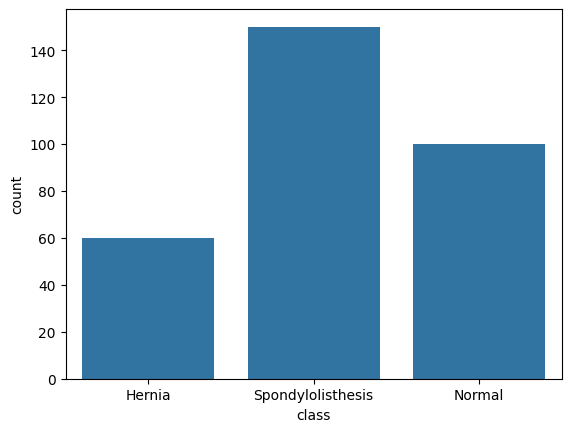

In [55]:
for col in cat_cols:
    cat_summary(df_3C, col, plot=True)


## Eksik Değerler

Veri seti üzerindeki gözlemlerde eksiklik olması durumudur. Bazı yerlerde NA olarak ifade edilir. 

Eksik değer problemleri Silme Yaklaşımı, Değer Atama Yöntemleri, Tahmine Dayalı Yöntemler ile çözülebilir.


Eksik veri ile çalışırken göz önünde bulundurulması gereken en önemli konulardan birisi eksik verinin rassallığıdır

Eğer eksiklikler değişkenler ile ilişkili olarak ortaya çıkan yapısal problemler ile meydana gelmiş ise bu durumda yapılacak silme işlemleri ciddi yanlılıklara sebep olabilecektir

Örneğin harcamaların betimlendiği bir veri setinde, kredi kartı harcama değişkenini düşünürsek, kredi kartı harcama gözlemlerinin bir kısmının NA olduğunu düşünelim. Eğer bu NA değerleri rastgele ortaya çıktıysa bir sorun teşkil etmemektedir. Bu durumda eksik veri problemli çözme tekniklerinden uygun olan bir yöntem seçerek işlem gerçekleştirilebilir.

Eksik değerlerin rastgele olmaması durumu ise ele aldığımız örnek üzerinde bir kullanıcının kredi kartı olmaması durumudur. Dolayısıyla kredi kartı harcaması 0 veya NA olacaktır. Şimdi burada NA durumu rastgele olarak betimlenememektedir. Çünkü kullanıcının kredi kartına sahip olma durumunu belirten başka bir değişkene bağlıdır.

Bir değişkendeki eksiklik, başka bir değişkenin etkisinde ortaya çıktığı durumlarda, bu yapısallığın nereden kaynaklandğına bakılıp, bu durum çözmeye çalışılabilir aksi halde yapacaığımız eksik değer problemini çözme teknikleri yanlılıklara sebep olacaktır.



In [56]:
for column in df_3C.columns:
    missing = df_3C[column].isnull()
    missing_count = missing.sum()
    total_count = len(df_3C)
    missing_percentage = 100 * missing_count / total_count
    
    print(f"\nSütun: {column}")
    print(f"Toplam veri sayısı: {total_count}")
    print(f"Eksik veri sayısı: {missing_count}")
    print(f"Eksik veri yüzdesi: {missing_percentage:.2f}%")
    print("Eksik değer var mı?: {}".format("Evet" if missing_count > 0 else "Hayır"))
    
    if missing_count > 0:
        print("\nEksik değerlerin indeksleri:")
        print(df_3C[df_3C[column].isnull()].index.tolist())
    
    print("Benzersiz değer sayısı:", df_3C[column].nunique())


Sütun: pelvic_incidence
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik değer var mı?: Hayır
Benzersiz değer sayısı: 310

Sütun: pelvic_tilt
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik değer var mı?: Hayır
Benzersiz değer sayısı: 310

Sütun: lumbar_lordosis_angle
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik değer var mı?: Hayır
Benzersiz değer sayısı: 280

Sütun: sacral_slope
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik değer var mı?: Hayır
Benzersiz değer sayısı: 281

Sütun: pelvic_radius
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik değer var mı?: Hayır
Benzersiz değer sayısı: 310

Sütun: degree_spondylolisthesis
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik değer var mı?: Hayır
Benzersiz değer sayısı: 310

Sütun: class
Toplam veri sayısı: 310
Eksik veri sayısı: 0
Eksik veri yüzdesi: 0.00%
Eksik de

## Outliers (Aykırı Değerler)

Veride genel eğilimin oldukça dışına çıkan ya da diğer gözlemlerden oldukça farklı olan gözlemlere Outlier denir.

Aykırı Değerler Neye Sebep Olur?

Genellenebilirlik kaygısı ile oluşturulan kural setlerini ya da fonksiyonları yanıltır ve yanlılığa sebep olur.

Aykırı değerler belirlenirken hangi aşamalar uygulanır

- Sektör Bilgisi

Sektör bilgisi üzerinde aksiyon almaya örnek olarak, konutların özellikleri ve fiyatlarını içeren bir veri setiyle çalışıldığında, verilerin genelinin temsil edildiği konut fiyat aralığının çok üzerinde olduğu düşünülen birkaç konut veri setinden çıkarılabilir

- Standart Sapma Yaklaşımı

Bu yaklaşım temel olarak, veriler üzerinde standart sapmalar gözlemlenerek, bu standart sapma değerlerinin oluşturduğu aralıkların dışında kalan verilerin çalışmanın dışında tutmak üzere kurulur

- Z-Skoru Yaklaşımı

Veri üzerinde gerçekleştirilen çeşitli istatistiki uygulamalarla belirlenen güven aralıkları kullanılarak aykırı değerlerin tespitinin yapılmasıdır

- Boxplot (Iqr) yöntemi (Tek değişkenli olarak)

Gözlem birimlerinin oluşturduğu aralıklara göre çizilmiş bir kutu grafik yardımıyla aykırı değerlerin belirlenmesi tekniğidir

- LOF yöntemi (Çok değişkenli olarak)

Local Outlier Factor yöntemi ile değişkenleri bir bütün olarak inceleyerek aykırı gözlemleri tespit edebiliriz. Bu yöntemi yapmadan önce, elmalarla armutları karşılaştırmamak adına, sayısal değişkenleri standartlaştırmak gerekecektir.

In [57]:
for col in num_cols:
    print(col, check_outlier(df_3C, col))

pelvic_incidence True
pelvic_tilt True
lumbar_lordosis_angle True
sacral_slope True
pelvic_radius True
degree_spondylolisthesis True


In [58]:
for col in num_cols:
    replace_with_thresholds(df_3C, col)

In [59]:
for col in num_cols:
    print(col, check_outlier(df_3C, col))

pelvic_incidence False
pelvic_tilt False
lumbar_lordosis_angle False
sacral_slope False
pelvic_radius False
degree_spondylolisthesis False


## Ölçeklendirme

Kategorik değişkenlerin sayısallaştırılması ile sayısal değişkenleri standartlaştırma işlemleri gerçekleştirilir. Bu işlem hem kategorik değişkenin modele uygun hale getirilmesi için, hem de bir değişken içerisinde baskın olan değerlerin fark edilebilmesine olanak sağlar.

- Kategorik değişkenler için ölçeklendirme (encoding)

Kategorik değişkenlerde, sıralı ve sırasız değişken farkına göre sayısallaştırma yapılmalıdır. Yani cinsiyet gibi herhangi bir sırası olmayan değişken ile, mezuniyet durumu gibi sıraya bağlı bir değişken aynı şekilde encode edilmemelidir. Sırasız değişkenler One Hot Encoding yapılmalı, yani değişkenin alacağı farklı değerlerin bir eksiği kadar yeni değişken türetilmeli, sıralı değişkenler için ise Label Encoding yani her bir farklı değer aşağıdan yukarıya sıralanacak şekilde düzenleme yapılmalıdır.

## Korelasyon Nedir

Korelasyon, iki değişken arasındaki ilişkiyi ifade eden bir istatistiksel kavramdır. 
Korelasyon katsayısı, iki değişkenin birbirleri ile nasıl ilişkili olduğunu gösteren bir ölçüdür.

Korelasyon katsayısının değeri -1 ile 1 arasında değişir.

- Korelasyon katsayısı 1 ise, iki değişken arasında pozitif tam bir ilişki vardır.
- Korelasyon katsayısı -1 ise, iki değişken arasında negatif tam bir ilişki vardır.
- Korelasyon katsayısı 0 ise, iki değişken arasında ilişki yoktur.


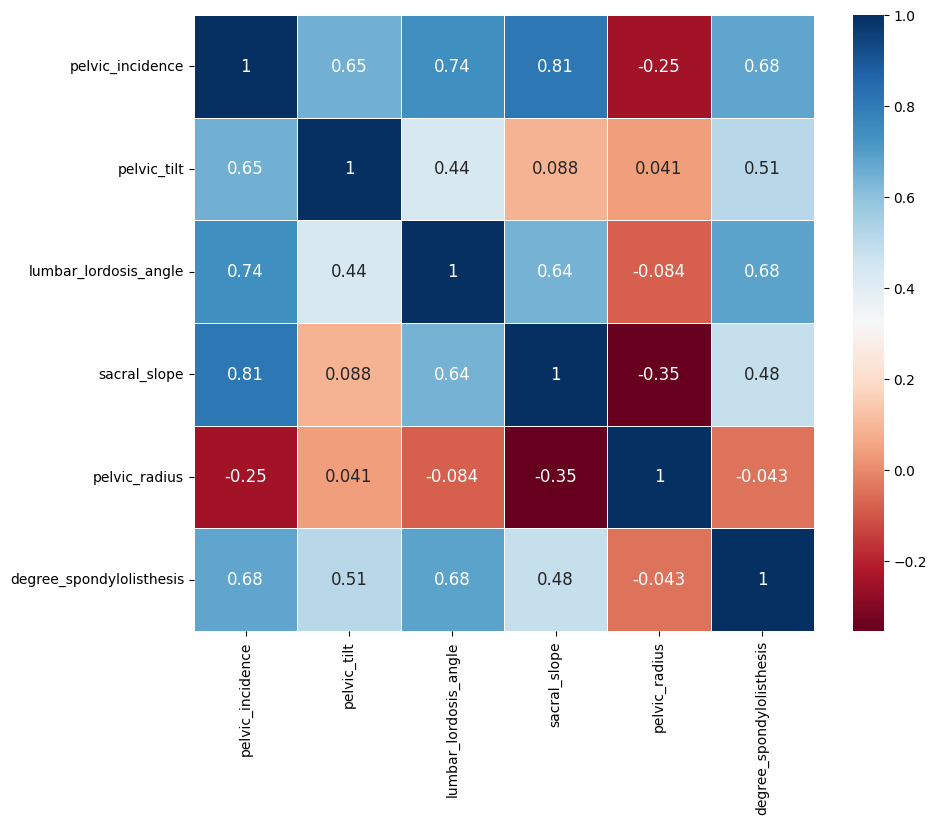

In [60]:
# Sayısal değişkenlerin birbirleri ile korelasyonu
correlation_matrix(df_3C, num_cols)

## Visualizing & Interpreting Data (Veri Görselleştirme ve Yorumlama)

Bu adım, ham veriyi anlamlı görsel temsillere dönüştürmeyi ve bu görselleri yorumlayarak veriden içgörüler elde etmeyi içerir. 

Yaygın görselleştirme teknikleri:
 - Histogramlar: Sürekli değişkenlerin dağılımını göstermek için
 - Kutu grafikleri(Boxplots): Veri dağılımını ve aykırı değerleri göstermek için
 - Scatter plots: İki değişken arasındaki ilişkiyi göstermek için
 - Çizgi grafikleri(Line plots): Zaman serisi verilerini göstermek için
 - Isı haritaları(Heatmaps): Çok boyutlu verilerdeki korelasyonları göstermek için


## Data Analysis by Grouping

Bu aşama, verileri belirli özelliklere göre kategorilere ayırarak incelemeyi içerir. 
Amaç:
- Veriyi daha anlamlı ve yönetilebilir parçalara ayırmak
- Gruplar içindeki ve arasındaki farklılıkları ve benzerlikleri belirlemek
- Spesifik alt gruplar için özetleyici istatistikler elde etmek

Gruplama kriterleri:
- Kategorik değişkenler: Örneğin, ülke, şehir, cinsiyet gibi
- Sayısal değişkenler: Örneğin, yaş, fiyat, puan gibi
- Zaman periyotları: Örneğin, ay, yıl, hafta gibi

Analiz teknikleri:
- Grup ortalamaları ve standart sapmaları
- Gruplar arası farklılıkları test etmek için istatistiksel testler
- Gruplar arası ilişkileri göstermek için korelasyon matrisleri



count    310.000000
mean      60.411958
std       16.945195
min       26.147921
5%        35.989222
10%       39.627082
20%       44.477560
30%       48.661127
40%       53.926470
50%       58.691038
60%       64.289637
70%       69.913140
80%       76.180575
90%       83.885248
95%       87.869063
max      112.548797
Name: pelvic_incidence, dtype: float64


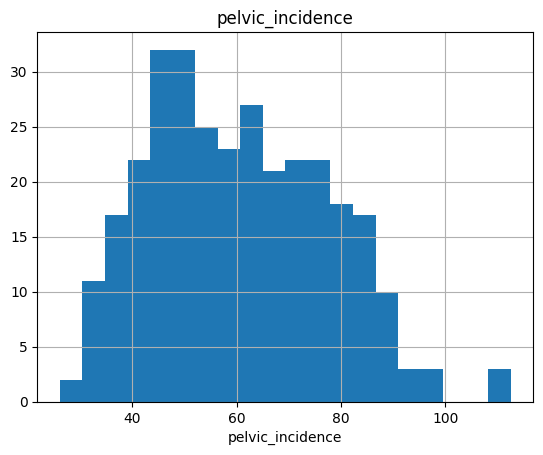

count    310.000000
mean      17.377847
std        9.578631
min       -6.512919
5%         3.383368
10%        6.548536
20%        9.699469
30%       12.886538
40%       14.150689
50%       16.357689
60%       18.793934
70%       20.699759
80%       24.233868
90%       32.003730
95%       37.549928
max       39.300383
Name: pelvic_tilt, dtype: float64


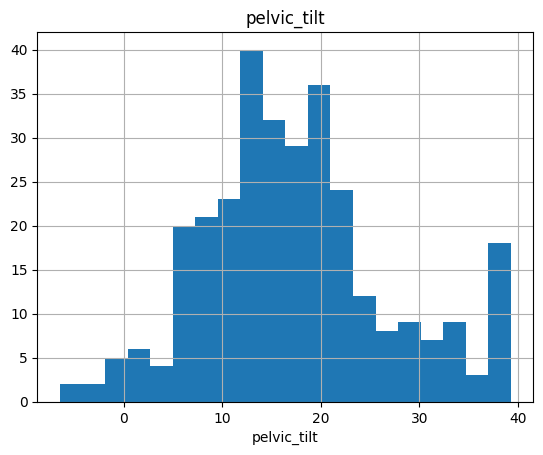

count    310.000000
mean      51.854341
std       18.295598
min       14.000000
5%        26.851671
10%       30.665404
20%       35.563797
30%       40.237770
40%       44.000000
50%       49.562398
60%       54.868854
70%       60.871346
80%       67.053422
90%       78.456030
95%       85.595495
max      102.000000
Name: lumbar_lordosis_angle, dtype: float64


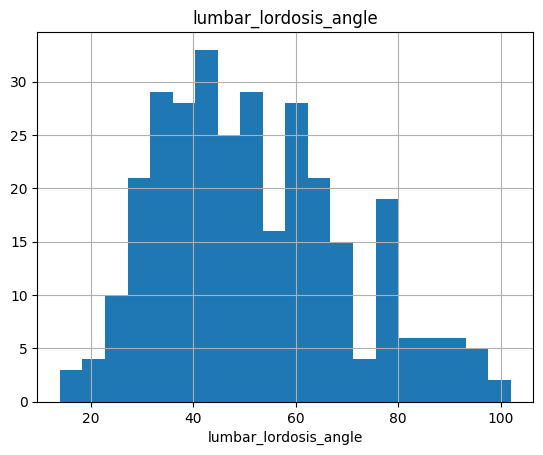

count    310.000000
mean      42.825732
std       12.848977
min       13.366931
5%        23.489452
10%       27.064456
20%       31.972798
30%       34.744184
40%       38.000305
50%       42.404912
60%       45.659512
70%       50.014013
80%       54.241126
90%       59.834863
95%       63.434949
max       81.719038
Name: sacral_slope, dtype: float64


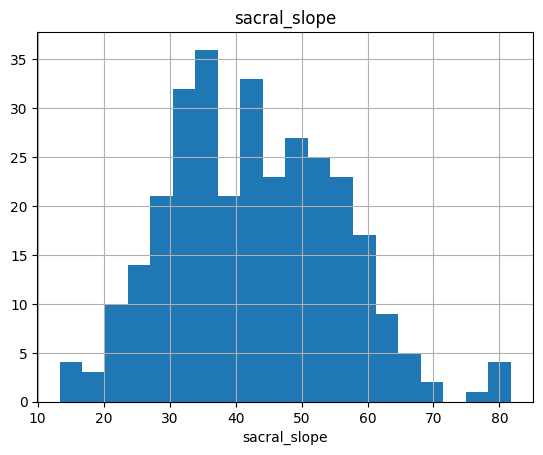

count    310.000000
mean     117.969164
std       12.635133
min       88.571479
5%        95.338541
10%      100.422318
20%      108.537398
30%      112.748573
40%      116.057566
50%      118.268178
60%      120.930051
70%      124.306251
80%      127.708285
90%      134.642039
95%      139.136036
max      147.605392
Name: pelvic_radius, dtype: float64


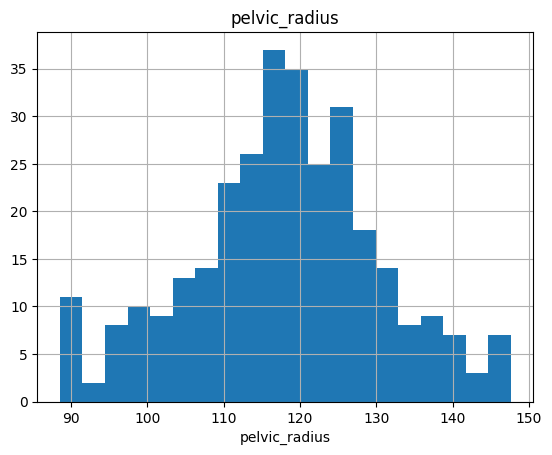

count    310.000000
mean      24.735864
std       28.812259
min      -11.058179
5%        -4.083136
10%       -2.097660
20%        0.491581
30%        2.591439
40%        5.877651
50%       11.767934
60%       27.305859
70%       36.737510
80%       51.877748
90%       67.831683
95%       81.691001
max      100.812790
Name: degree_spondylolisthesis, dtype: float64


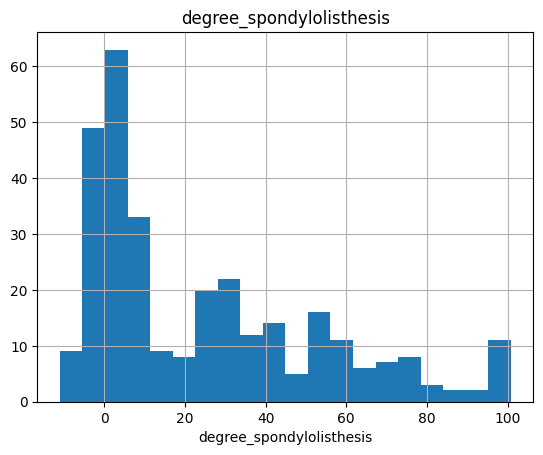

In [61]:
# sayısal sütunların istatistiksel özetini ve dağılımını gösterir
for col in num_cols:
    num_summary(df_3C, col, plot=True)

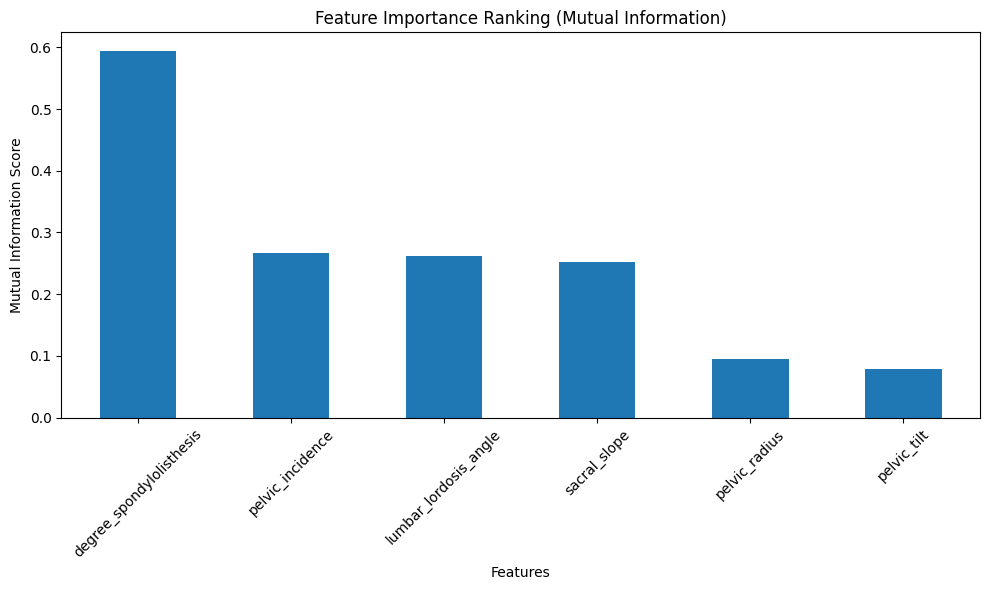

In [62]:
# Özellik Önem Sıralaması
X = df_3C.drop('class', axis=1)
y = df_3C['class']
mi_scores = mutual_info_classif(X, y)
mi_scores = pd.Series(mi_scores, index=X.columns)
mi_scores = mi_scores.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
mi_scores.plot(kind='bar')
plt.title(f'Feature Importance Ranking (Mutual Information)')
plt.xlabel('Features')
plt.ylabel('Mutual Information Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

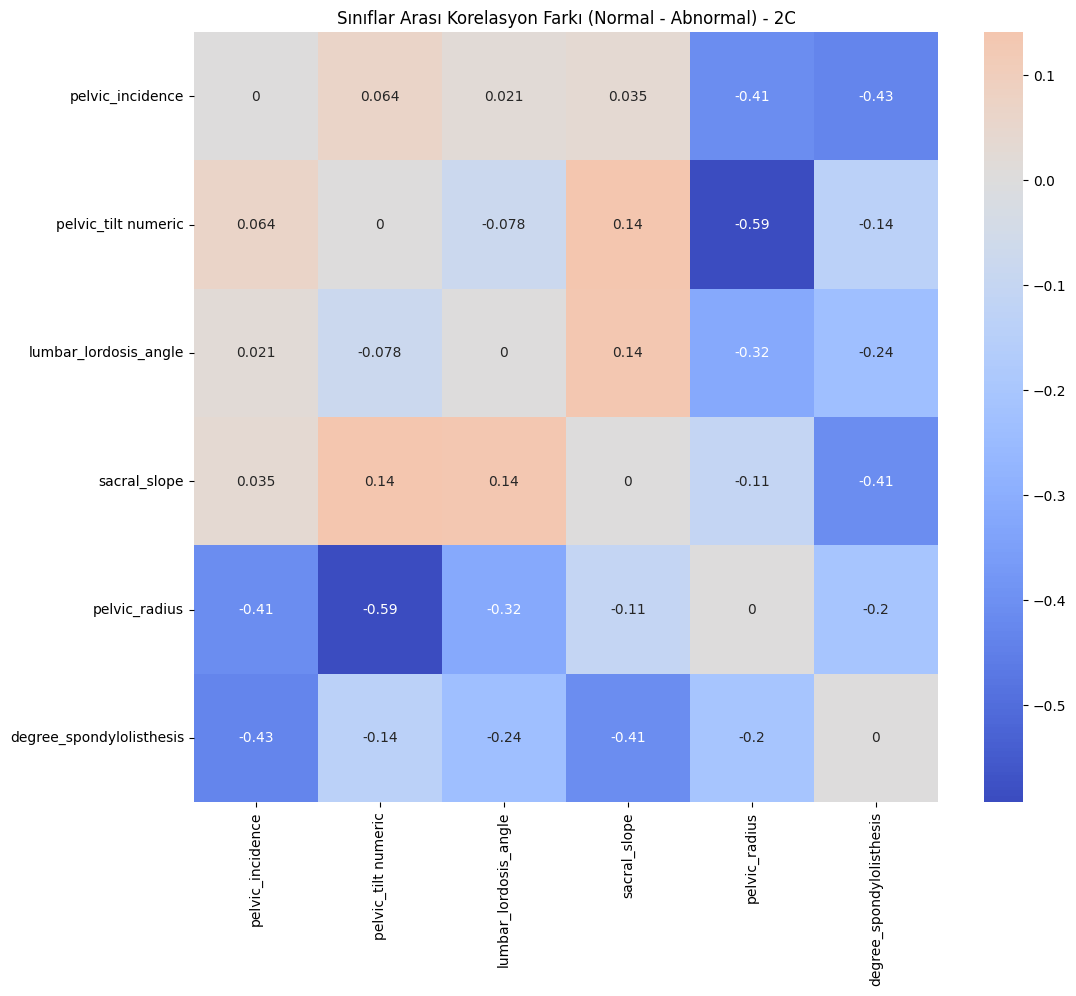

In [63]:
numeric_columns = df_2C.select_dtypes(include=[np.number]).columns

# Sınıflar Arası Korelasyon Farkı
classes = df_2C['class'].unique()
for i in range(len(classes)):
    for j in range(i+1, len(classes)):
        class1, class2 = classes[i], classes[j]
        corr1 = df_2C[df_2C['class'] == class1][numeric_columns].corr()
        corr2 = df_2C[df_2C['class'] == class2][numeric_columns].corr()
        corr_diff = corr2 - corr1
        
        plt.figure(figsize=(12, 10))
        sns.heatmap(corr_diff, annot=True, cmap='coolwarm', center=0)
        plt.title(f'Sınıflar Arası Korelasyon Farkı ({class2} - {class1}) - {"2C"}')
        plt.show()

                   pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  \
class                                                                     
Hernia                    47.638407    17.361179              35.463524   
Normal                    51.685244    12.821414              43.542605   
Spondylolisthesis         71.339187    20.422135              63.951826   

                   sacral_slope  pelvic_radius  degree_spondylolisthesis  
class                                                                     
Hernia                30.239612     116.547136                  2.480251  
Normal                38.863830     123.887942                  2.186572  
Spondylolisthesis     50.501449     114.592123                 48.670971  


<Figure size 1200x600 with 0 Axes>

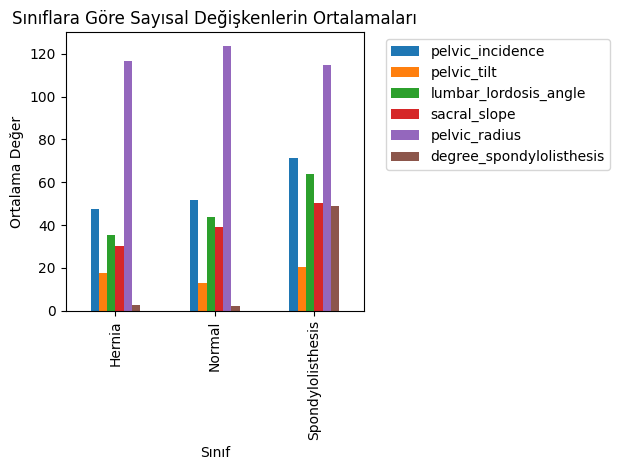

In [64]:
sinif_gruplama = df_3C.groupby('class')[num_cols].mean()
print(sinif_gruplama)

# Görselleştirme
plt.figure(figsize=(12, 6))
sinif_gruplama.plot(kind='bar')
plt.title('Sınıflara Göre Sayısal Değişkenlerin Ortalamaları')
plt.xlabel('Sınıf')
plt.ylabel('Ortalama Değer')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

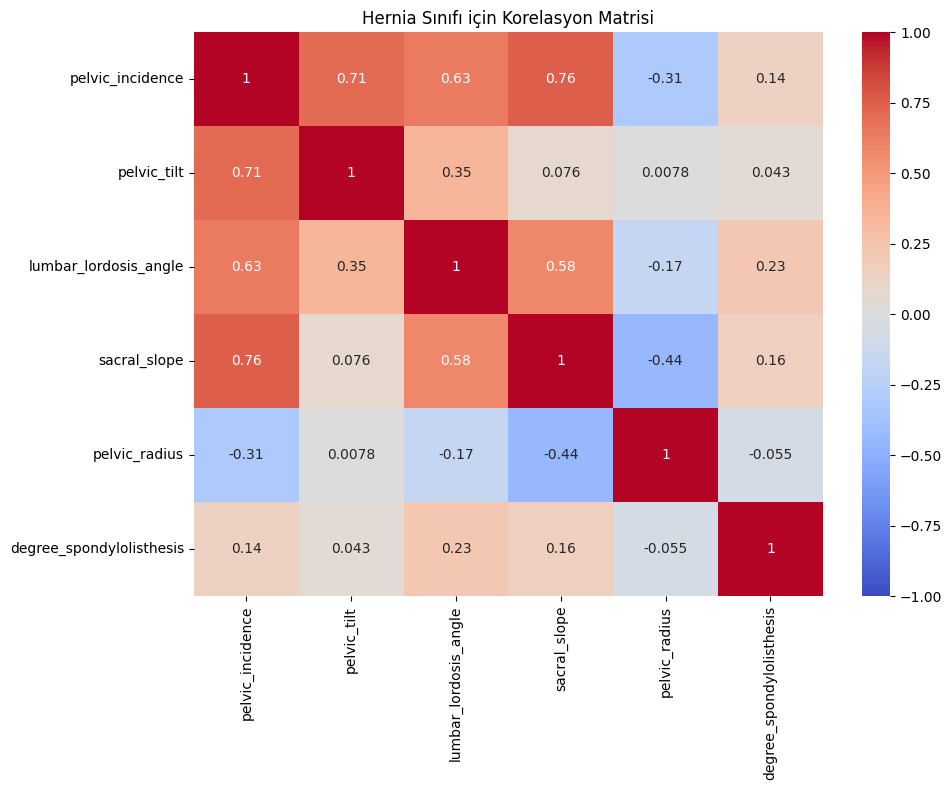

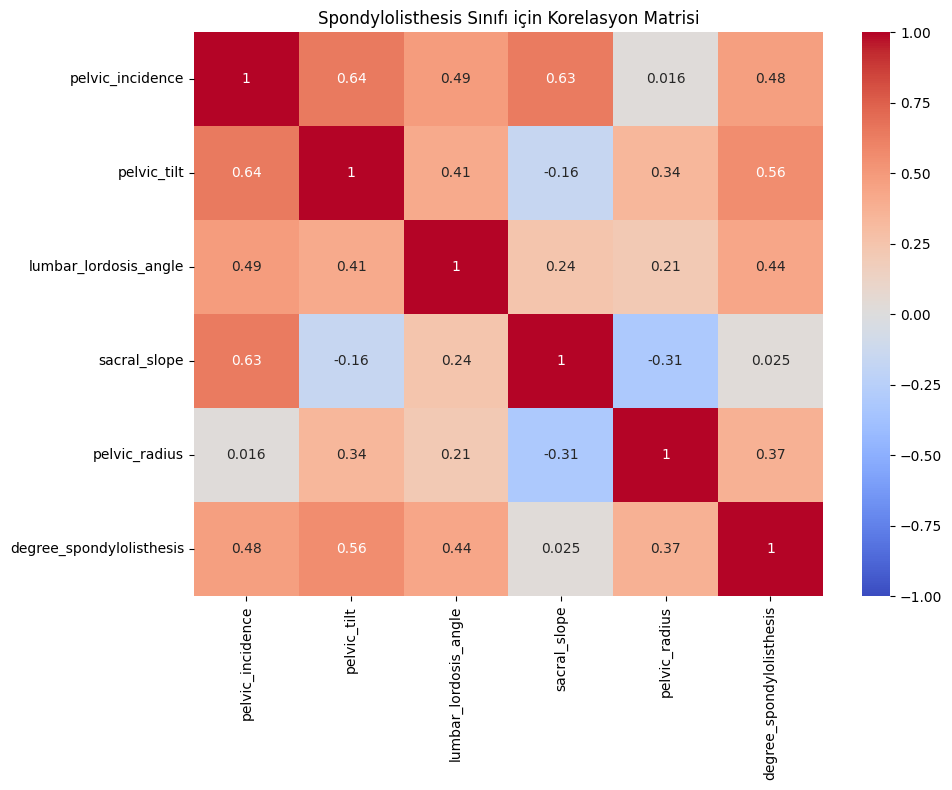

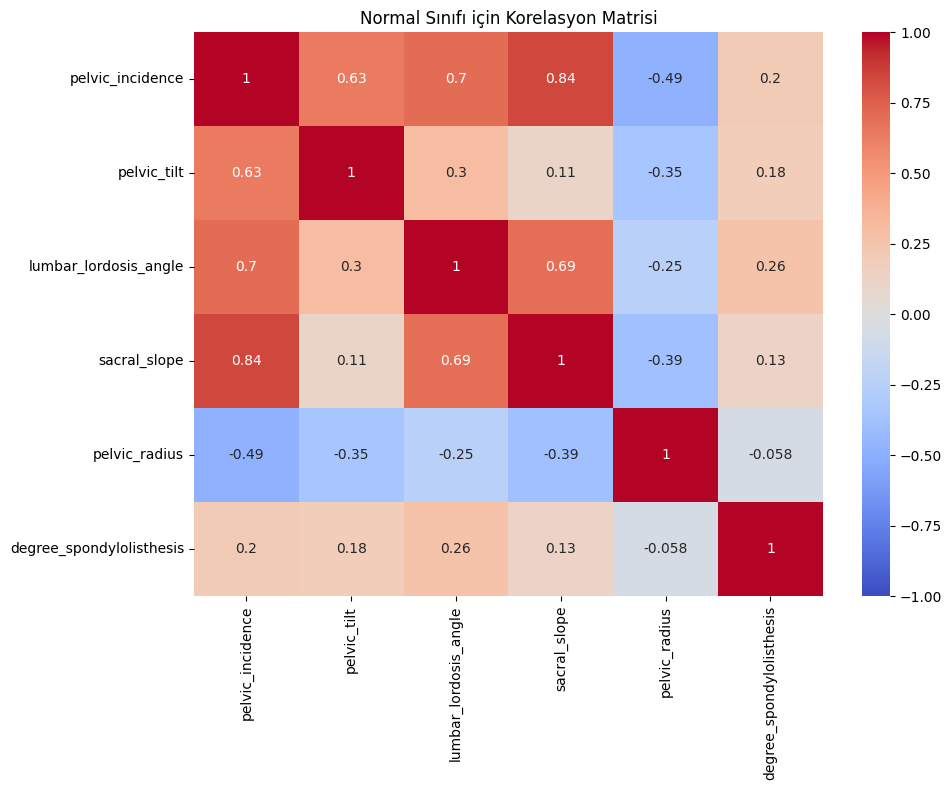

In [65]:
for sinif in df_3C['class'].unique():
    corr = df_3C[df_3C['class'] == sinif][num_cols].corr()
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)
    plt.title(f'{sinif} Sınıfı için Korelasyon Matrisi')
    plt.tight_layout()
    plt.show()

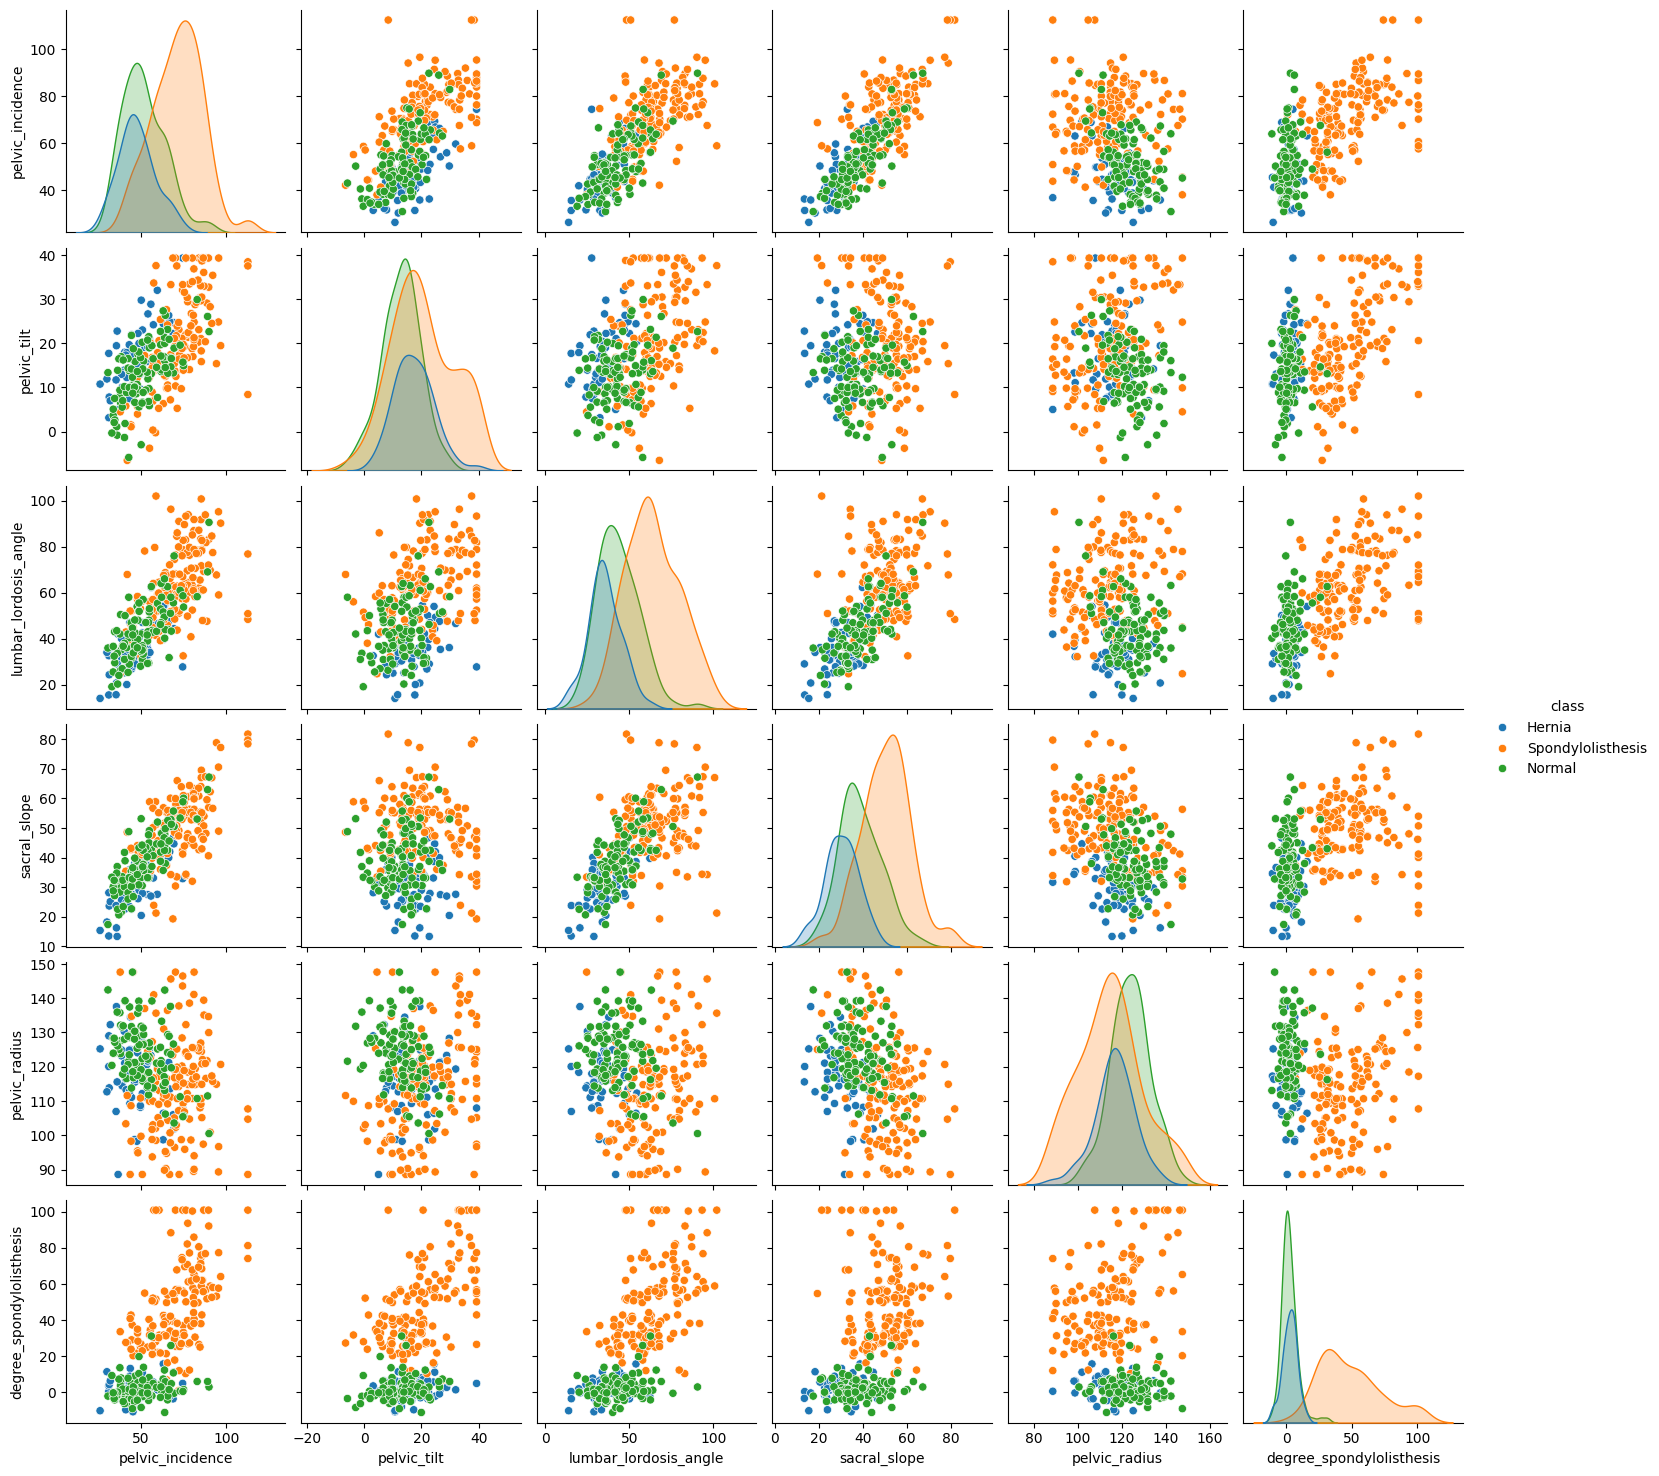

In [66]:
# Sayısal değişkenlerin birbirleriyle olan ilişkisi
sns.pairplot(df_3C, hue='class')
plt.show()

In [67]:
numeric_features = df_3C.select_dtypes(include=['float64', 'int64']).columns

In [68]:
X = df_3C[numeric_features]
y = df_3C['class']

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [71]:
# Özellikleri ölçeklendirme
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [72]:
# Random Forest modelini oluşturma ve eğitme
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

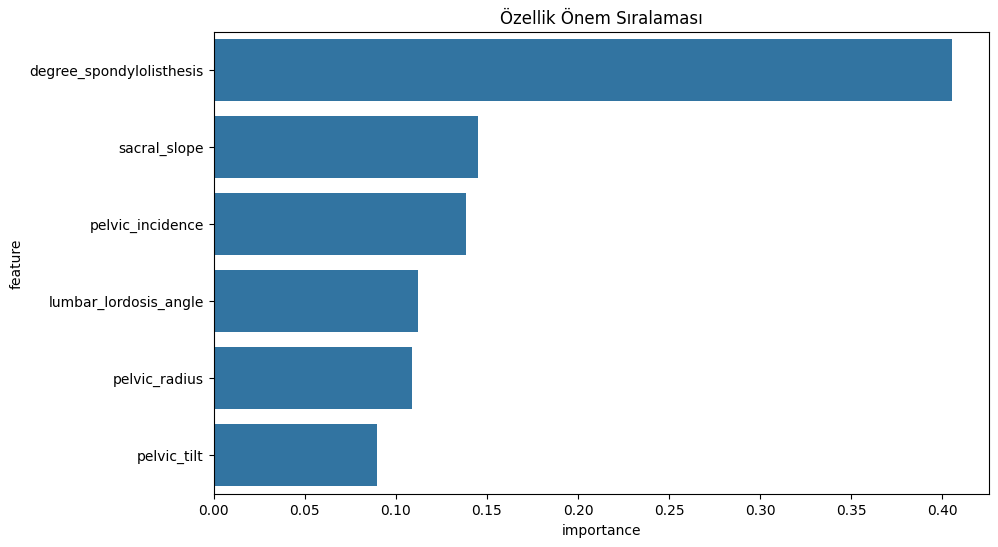

In [73]:
# Özellik önemini görüntüleme
feature_importance = pd.DataFrame({'feature': numeric_features, 'importance': rf_model.feature_importances_})
feature_importance = feature_importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance)
plt.title('Özellik Önem Sıralaması')
plt.show()

In [74]:
y_pred = rf_model.predict(X_test_scaled)

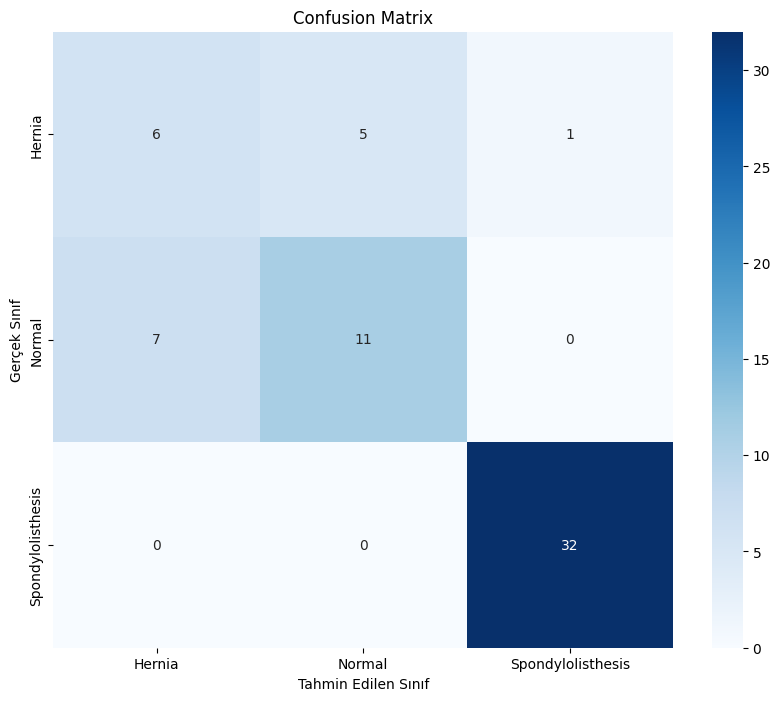


Classification Report:
                   precision    recall  f1-score   support

           Hernia       0.46      0.50      0.48        12
           Normal       0.69      0.61      0.65        18
Spondylolisthesis       0.97      1.00      0.98        32

         accuracy                           0.79        62
        macro avg       0.71      0.70      0.70        62
     weighted avg       0.79      0.79      0.79        62



In [75]:
cm = confusion_matrix(y_test, y_pred)

class_labels = rf_model.classes_

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

In [76]:
# Örnek tahminler
ornek_girdiler = [
    [63.0278175, 22.55258597, 39.60911701, 40.47523153, 98.67291675, -0.254399986],
    [39.05695098, 10.06099147, 25.01537822, 28.99595951, 114.4054254, 4.564258645],
    [51.31177106, 8.875541276, 56.99999999, 42.43622979, 126.4722584, -2.144043911],
    [45.25279209, 8.693157364, 41.5831264, 36.55963472, 118.5458418, 0.214750167]
]

In [77]:
ornek_girdiler_scaled = scaler.transform(ornek_girdiler)
tahminler = rf_model.predict(ornek_girdiler_scaled)
tahmin_olasiliklari = rf_model.predict_proba(ornek_girdiler_scaled)

c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [78]:

print("\nÖrnek Tahminler:")
for i, (tahmin, olasiliklar) in enumerate(zip(tahminler, tahmin_olasiliklari)):
    print(f"Örnek {i+1} için tahmin: {tahmin}")
    for j, sinif in enumerate(rf_model.classes_):
        print(f"{sinif} olma olasılığı: {olasiliklar[j]:.2f}")
    print()


Örnek Tahminler:
Örnek 1 için tahmin: Hernia
Hernia olma olasılığı: 0.86
Normal olma olasılığı: 0.13
Spondylolisthesis olma olasılığı: 0.01

Örnek 2 için tahmin: Hernia
Hernia olma olasılığı: 0.84
Normal olma olasılığı: 0.16
Spondylolisthesis olma olasılığı: 0.00

Örnek 3 için tahmin: Normal
Hernia olma olasılığı: 0.03
Normal olma olasılığı: 0.96
Spondylolisthesis olma olasılığı: 0.01

Örnek 4 için tahmin: Normal
Hernia olma olasılığı: 0.03
Normal olma olasılığı: 0.97
Spondylolisthesis olma olasılığı: 0.00

